## Carga y configuración inicial

In [ ]:
import pandas as pd

import numpy as np

from math import radians, cos, sin, asin, sqrt



# ── Carga de ficheros GTFS originales ──────────────────────

routes    = pd.read_csv('routes.txt')

trips     = pd.read_csv('trips.txt')

st        = pd.read_csv('stop_times.txt')

stops     = pd.read_csv('stops.txt')

shapes    = pd.read_csv('shapes.txt')

calendar  = pd.read_csv('calendar_dates.txt')

agency    = pd.read_csv('agency.txt')

## Correcciones en tablas base

In [ ]:
# ── routes: completar route_short_name y añadir agency ──────

routes['route_short_name'] = routes['route_id'].astype(str)



# ── trips: añadir direction_label legible ─────────────────────

trips['direction_label'] = trips['direction_id'].map({0:'Ida', 1:'Vuelta'})



# ── stop_times: campo bajo petición ─────────────────────────

st['bajo_peticion'] = st['pickup_type'] == 2



# ── calendar_dates: parsear fecha y extraer componentes ──────

calendar['fecha'] = pd.to_datetime(

    calendar['date'].astype(str), format='%Y%m%d'

)

calendar['year']         = calendar['fecha'].dt.year

calendar['month']        = calendar['fecha'].dt.month

meses_es = {
    1:'Enero',    2:'Febrero',   3:'Marzo',     4:'Abril',
    5:'Mayo',     6:'Junio',     7:'Julio',      8:'Agosto',
    9:'Septiembre', 10:'Octubre', 11:'Noviembre', 12:'Diciembre'
}
calendar['month_name'] = calendar['month'].map(meses_es)

calendar['day_of_week']  = calendar['fecha'].dt.dayofweek   # 0=Lunes

dias_es = {
    0:'Lunes', 1:'Martes', 2:'Miércoles', 3:'Jueves',
    4:'Viernes', 5:'Sábado', 6:'Domingo'
}
calendar['day_name'] = calendar['day_of_week'].map(dias_es)

calendar['is_weekend']   = calendar['day_of_week'] >= 5

## Función de distancia (haversine)

In [ ]:
def haversine(lat1, lon1, lat2, lon2):

    """Distancia en km entre dos puntos GPS."""

    R = 6371

    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1

    dlon = lon2 - lon1

    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2

    return 2 * R * asin(sqrt(a))



def distancia_shape(df_shape):

    """Distancia total de un shape ordenando los puntos."""

    df = df_shape.sort_values('shape_pt_sequence')

    dist = 0.0

    for i in range(len(df) - 1):

        dist += haversine(

            df.iloc[i]['shape_pt_lat'],  df.iloc[i]['shape_pt_lon'],

            df.iloc[i+1]['shape_pt_lat'], df.iloc[i+1]['shape_pt_lon']

        )

    return round(dist, 2)



# Calcular distancia para cada shape_id

print('Calculando distancias... (tarda ~30 segundos)')

dist_por_shape = (

    shapes

    .groupby('shape_id')

    .apply(distancia_shape, include_groups=False)

    .reset_index()

    .rename(columns={0:'distancia_km'})

)



# Distancia media por ruta (una ruta puede tener varios shapes)

dist_por_ruta = (

    trips[['route_id','shape_id']].drop_duplicates()

    .merge(dist_por_shape, on='shape_id')

    .groupby('route_id')['distancia_km']

    .mean()

    .reset_index()

    .rename(columns={'distancia_km':'distancia_media_km'})

)

Calculando distancias... (tarda ~30 segundos)


## Tabla: detalle_trips_enriquecido.csv

In [ ]:
# Hora de inicio de cada trip (arrival_time de la primera parada)

hora_inicio = (

    st.loc[st.groupby('trip_id')['stop_sequence'].idxmin(),

           ['trip_id','arrival_time']]

    .rename(columns={'arrival_time':'hora_inicio_str'})

)

hora_inicio['hora_inicio'] = (

    hora_inicio['hora_inicio_str'].str.split(':').str[0].astype(int)

)

In [ ]:
# Tiempo de recorrido: diferencia entre última y primera parada

def str_to_min(t):

    """'HH:MM:SS' -> minutos totales (soporta >24h como 25:30:00)"""

    h, m, s = map(int, t.split(':'))

    return h * 60 + m + s / 60



st['minutos'] = st['arrival_time'].apply(str_to_min)

duracion = (

    st.groupby('trip_id')['minutos']

    .agg(lambda x: round(x.max() - x.min(), 1))

    .reset_index()

    .rename(columns={'minutos':'tiempo_recorrido_min'})

)



# Paradas bajo petición por trip

bp_por_trip = (

    st.groupby('trip_id')['bajo_peticion']

    .agg(

        num_paradas_trip=('count'),

        num_bajo_peticion=('sum'),

        tiene_bajo_peticion=('any')

    )

    .reset_index()

)



# Franja horaria

def franja(h):

    if h < 6:  return 'Madrugada'

    if h < 12: return 'Mañana'

    if h < 15: return 'Mediodía'

    if h < 20: return 'Tarde'

    return 'Noche'



# Unir todo

df_trips = (

    trips

    .merge(routes[['route_id','route_long_name','agency_name']], on='route_id')

    .merge(hora_inicio, on='trip_id')

    .merge(duracion,    on='trip_id')

    .merge(bp_por_trip, on='trip_id')

)

df_trips['franja_horaria'] = df_trips['hora_inicio'].apply(franja)



# Número de días activos por servicio (desde calendar_dates)

dias_activos = (

    calendar.groupby('service_id')['fecha']

    .nunique()

    .reset_index()

    .rename(columns={'fecha':'num_dias_activo'})

)

df_trips = df_trips.merge(dias_activos, on='service_id', how='left')



# Exportar

df_trips.to_csv('detalle_trips_enriquecido.csv', index=False)

print(f'Trips enriquecidos: {len(df_trips)} filas')



Trips enriquecidos: 492 filas


## 4.5 Tabla: resumen_por_ruta.csv

In [ ]:
# Paradas únicas y bajo petición por ruta

paradas_ruta = (

    st.merge(trips[['trip_id','route_id']], on='trip_id')

    .groupby('route_id')

    .agg(

        num_paradas_unicas   = ('stop_id', 'nunique'),

        num_bajo_peticion    = ('bajo_peticion', 'sum'),

    )

    .reset_index()

)

paradas_ruta['pct_bajo_peticion'] = (

    paradas_ruta['num_bajo_peticion'] /

    paradas_ruta['num_paradas_unicas'] * 100

).round(1)



# Expediciones por ruta y dirección

exp_dir = (

    trips.groupby(['route_id','direction_id'])['trip_id']

    .nunique()

    .unstack(fill_value=0)

    .rename(columns={0:'exp_ida', 1:'exp_vuelta'})

    .reset_index()

)



# Horas primera/última expedición por ruta

horas_ruta = (

    df_trips.groupby('route_id')['hora_inicio']

    .agg(hora_primera=min, hora_ultima=max)

    .reset_index()

)



# Tiempo medio de recorrido por ruta

tiempo_ruta = (

    df_trips.groupby('route_id')['tiempo_recorrido_min']

    .mean()

    .round(1)

    .reset_index()

    .rename(columns={'tiempo_recorrido_min':'tiempo_recorrido_medio_min'})

)



# Combinar todo

df_rutas = (

    routes

    .merge(exp_dir,       on='route_id', how='left')

    .merge(paradas_ruta,  on='route_id', how='left')

    .merge(dist_por_ruta, on='route_id', how='left')

    .merge(horas_ruta,    on='route_id', how='left')

    .merge(tiempo_ruta,   on='route_id', how='left')

)

df_rutas['num_expediciones'] = df_rutas['exp_ida'] + df_rutas['exp_vuelta']


# Días activos por ruta (desde calendar_dates + trips)
dias_activos = (
    calendar
    .merge(trips[['trip_id', 'service_id', 'route_id']], on='service_id')
    .groupby('route_id')['fecha']
    .nunique()
    .reset_index()
    .rename(columns={'fecha': 'num_dias_activo'})
)

df_rutas = df_rutas.merge(dias_activos, on='route_id', how='left')

# Calcular frecuencia diaria media
df_rutas['frecuencia_diaria_media'] = (
    df_rutas['num_expediciones'] / df_rutas['num_dias_activo']
).round(2)

# Exportar
df_rutas.to_csv('resumen_por_ruta.csv', index=False)



print(df_rutas[['route_long_name','num_expediciones',

               'num_paradas_unicas','distancia_media_km',

               'pct_bajo_peticion']].to_string())

                                   route_long_name  num_expediciones  num_paradas_unicas  distancia_media_km  pct_bajo_peticion
0             Pamplona/Iruña-Soria (por carretera)                 2                  20          193.675000                0.0
1             Pamplona/Iruña-Soria (por autopista)                38                  10          148.240000                0.0
2               Tafalla-Pamplona/Iruña (autopista)                16                  10           37.972500                0.0
3     Olite/Erriberri - Pamplona/Iruña (autopista)                24                  15           44.660000                0.0
4             Tafalla - Pamplona/Iruña (carretera)                24                  26           42.844286                0.0
5                                Marcilla -Tafalla                21                  19           61.875000                0.0
6                                Figarol - Tafalla                18                  21           53.95

/tmp/ipykernel_686/1334900527.py:55: FutureWarning: The provided callable <built-in function min> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  .agg(hora_primera=min, hora_ultima=max)
/tmp/ipykernel_686/1334900527.py:55: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  .agg(hora_primera=min, hora_ultima=max)


## 4.6 Tabla: paradas_enriquecidas.csv

In [ ]:
# Rutas y trips que pasan por cada parada

uso_paradas = (

    st.merge(trips[['trip_id','route_id']], on='trip_id')

    .groupby('stop_id')

    .agg(

        num_rutas_que_pasan = ('route_id', 'nunique'),

        num_trips_que_pasan = ('trip_id',  'nunique'),

        es_bajo_peticion    = ('bajo_peticion', 'any'),

    )

    .reset_index()

)



# Agencias que pasan por cada parada

agencias_parada = (

    st.merge(trips[['trip_id','route_id']], on='trip_id')

      .merge(routes[['route_id','agency_name']], on='route_id')

      .groupby('stop_id')['agency_name']

      .apply(lambda x: ', '.join(sorted(x.unique())))

      .reset_index()

      .rename(columns={'agency_name':'agencias_que_pasan'})

)



# Nivel de hub

def nivel_hub(n):

    if n >= 10: return 'Intercambiador'

    if n >= 3:  return 'Multi-ruta'

    return 'Parada simple'



df_stops = (

    stops          # ya sin stop_url

    .merge(uso_paradas,    on='stop_id', how='left')

    .merge(agencias_parada, on='stop_id', how='left')

)

df_stops['nivel_hub'] = df_stops['num_rutas_que_pasan'].apply(nivel_hub)



df_stops.to_csv('paradas_enriquecidas.csv', index=False)

print(df_stops[['stop_name','num_rutas_que_pasan','nivel_hub','agencias_que_pasan']]

     .sort_values('num_rutas_que_pasan', ascending=False)

     .head(10).to_string())

                                          stop_name  num_rutas_que_pasan       nivel_hub                                  agencias_que_pasan
18                          Tafalla. c/ Recoletas 7                   15  Intercambiador                      Conda S.A., Inter-Arriaga S.L.
0   Pamplona/Iruña. Estación Bus. Yanguas y Miranda                   14  Intercambiador  Conda S.A., Inter-Arriaga S.L., La Burundesa S.A.U
2                          Tafalla. c/ Recoletas 14                   14  Intercambiador                      Conda S.A., Inter-Arriaga S.L.
3        Tafalla. Intercambiador Bus. c/ Pesquera 1                   13  Intercambiador                      Conda S.A., Inter-Arriaga S.L.
19                   Tafalla. Av. Baja Navarra F/13                   10  Intercambiador                      Conda S.A., Inter-Arriaga S.L.
23                     Pamplona/Iruña. c/ Sadar F/6                   10  Intercambiador              Inter-Arriaga S.L., La Burundesa S.A.U
20         Tu

## 4.7 Tabla: actividad_temporal.csv

In [ ]:
# Join trips + calendar_dates + routes para tener fecha real por expedición

df_temporal = (

    trips[['trip_id','route_id','service_id','direction_label']]

    .merge(

        calendar[['service_id','fecha','year','month',

                  'month_name','day_of_week','day_name','is_weekend']],

        on='service_id'

    )

    .merge(

        routes[['route_id','route_long_name','agency_name']],

        on='route_id'

    )

    .merge(df_trips[['trip_id','hora_inicio','franja_horaria']],

        on='trip_id'

    )

)
# Guardar solo años con datos representativos (2022-2025)

df_temporal = df_temporal[df_temporal['year'] >= 2022]



df_temporal.to_csv('actividad_temporal.csv', index=False)

print(f'Filas en actividad_temporal: {len(df_temporal):,}')

print(df_temporal.groupby('year')['trip_id'].nunique())




Filas en actividad_temporal: 268,381
year
2022    251
2023    451
2024    481
2025    473
Name: trip_id, dtype: int64


In [ ]:
df = pd.read_csv('resumen_por_ruta.csv')
print(df[['route_long_name', 'exp_ida', 'exp_vuelta']].to_string())

                                   route_long_name  exp_ida  exp_vuelta
0             Pamplona/Iruña-Soria (por carretera)        1           1
1             Pamplona/Iruña-Soria (por autopista)       20          18
2               Tafalla-Pamplona/Iruña (autopista)        7           9
3     Olite/Erriberri - Pamplona/Iruña (autopista)       13          11
4             Tafalla - Pamplona/Iruña (carretera)       13          11
5                                Marcilla -Tafalla       11          10
6                                Figarol - Tafalla       10           8
7                                   Rada - Tafalla       10           9
8                            Mendigorría - Tafalla        4           3
9                        Miranda de Arga - Tafalla        6           5
10                                  Urbano Tafalla       21           0
11                               Echagüe - Tafalla        6           6
12                                Olleta - Tafalla        6     

In [ ]:
import pandas as pd

rs = pd.read_csv('route_stops_unique_fixed.csv')
at = pd.read_csv('actividad_temporal.csv')

# Paradas únicas por año y ruta
paradas_por_año = (
    at[['route_id', 'year']].drop_duplicates()
    .merge(rs[['route_id', 'stop_id']], on='route_id')
    .groupby('year')['stop_id']
    .nunique()
    .reset_index()
    .rename(columns={'stop_id': 'num_paradas_unicas'})
)

print(paradas_por_año)

   year  num_paradas_unicas
0  2022                 112
1  2023                 222
2  2024                 222
3  2025                 222


In [ ]:
import pandas as pd

rs = pd.read_csv('route_stops_unique_fixed.csv')
at = pd.read_csv('actividad_temporal.csv')

# Paradas únicas por año, ruta y agencia
paradas_por_año = (
    at[['route_id', 'year', 'agency_name']].drop_duplicates()
    .merge(rs[['route_id', 'stop_id', 'route_long_name']], on='route_id')
    .groupby(['year', 'route_id', 'route_long_name', 'agency_name'])['stop_id']
    .nunique()
    .reset_index()
    .rename(columns={'stop_id': 'num_paradas_unicas'})
)

paradas_por_año.to_csv('paradas_por_año.csv', index=False)
print(paradas_por_año.head(10))
print(f"Total filas: {len(paradas_por_año)}")

   year  route_id                               route_long_name  \
0  2022       300          Pamplona/Iruña-Soria (por carretera)   
1  2022       301          Pamplona/Iruña-Soria (por autopista)   
2  2022       320            Tafalla-Pamplona/Iruña (autopista)   
3  2022       321  Olite/Erriberri - Pamplona/Iruña (autopista)   
4  2022       322          Tafalla - Pamplona/Iruña (carretera)   
5  2022       323                             Marcilla -Tafalla   
6  2022       324                             Figarol - Tafalla   
7  2022       325                                Rada - Tafalla   
8  2022       326                         Mendigorría - Tafalla   
9  2022       327                     Miranda de Arga - Tafalla   

          agency_name  num_paradas_unicas  
0          Conda S.A.                  20  
1          Conda S.A.                  10  
2  Inter-Arriaga S.L.                  10  
3  Inter-Arriaga S.L.                  15  
4  Inter-Arriaga S.L.                  26 

In [ ]:
import pandas as pd

df = pd.read_csv('paradas_por_año.csv')
print(df['year'].value_counts().sort_index())

year
2022    18
2023    29
2024    32
2025    32
Name: count, dtype: int64


In [ ]:
import pandas as pd
df = pd.read_csv('paradas_municipio.csv')
print(df.columns.tolist())
print(df.head(3))

['stop_id', 'stop_name', 'stop_lat', 'stop_lon', 'cod_municipio', 'municipio_mapa', 'tipo_asignacion']
   stop_id                                        stop_name   stop_lat  \
0     3031  Pamplona/Iruña. Estación Bus. Yanguas y Miranda  42.811366   
1     3536                      Tafalla. Av. Baja Navarra 7  42.531627   
2     3122                         Tafalla. c/ Recoletas 14  42.526197   

   stop_lon  cod_municipio municipio_mapa         tipo_asignacion  
0 -1.645310          31201       Pamplona  punto_dentro_municipio  
1 -1.672542          31227        Tafalla  punto_dentro_municipio  
2 -1.675640          31227        Tafalla  punto_dentro_municipio  


In [ ]:
import pandas as pd
poblacion = pd.read_csv('municipios_navarra.csv')
print(poblacion.columns.tolist())
print(poblacion.head(3))
print(f"Total filas: {len(poblacion)}")

['cod_municipio', 'municipio', 'sexo', 'anio', 'poblacion']
   cod_municipio municipio   sexo  anio  poblacion
0          31001   Abáigar  Total  2018         87
1          31001   Abáigar  Total  2019         83
2          31001   Abáigar  Total  2020         82
Total filas: 1904


In [ ]:
import pandas as pd

# ──────────────────────────────────────────────
# Cargar datos
# ──────────────────────────────────────────────
trips = pd.read_csv('trips.txt')
stop_times = pd.read_csv('stop_times.txt')
calendar = pd.read_csv('calendar_dates.txt')
paradas_municipio = pd.read_csv('paradas_municipio.csv')
poblacion = pd.read_csv('municipios_navarra.csv')

# ──────────────────────────────────────────────
# Preparar calendar
# ──────────────────────────────────────────────
calendar['fecha'] = pd.to_datetime(calendar['date'].astype(str), format='%Y%m%d')
calendar['year'] = calendar['fecha'].dt.year
calendar = calendar[calendar['exception_type'] == 1]

# ──────────────────────────────────────────────
# Cruces principales
# ──────────────────────────────────────────────
trips_fechas = trips.merge(
    calendar[['service_id', 'fecha', 'year']], on='service_id'
)
trips_paradas = trips_fechas.merge(
    stop_times[['trip_id', 'stop_id']], on='trip_id'
)
trips_muni = trips_paradas.merge(
    paradas_municipio[['stop_id', 'cod_municipio', 'municipio_mapa']], on='stop_id'
)

# ──────────────────────────────────────────────
# 1. Servicios medios diarios por municipio y año
# ──────────────────────────────────────────────
servicios_diarios = (
    trips_muni
    .groupby(['cod_municipio', 'municipio_mapa', 'year'])
    .agg(
        num_servicios_totales=('trip_id', 'count'),
        num_dias_activos=('fecha', 'nunique')
    )
    .reset_index()
)
servicios_diarios['servicios_medios_diarios'] = (
    servicios_diarios['num_servicios_totales'] / servicios_diarios['num_dias_activos']
).round(2)

# ──────────────────────────────────────────────
# 2. Nº paradas únicas por municipio y año
# ──────────────────────────────────────────────
paradas_unicas = (
    trips_muni[['year', 'cod_municipio', 'municipio_mapa', 'stop_id']]
    .drop_duplicates()
    .groupby(['cod_municipio', 'municipio_mapa', 'year'])
    .size()
    .reset_index(name='num_paradas_municipio')
)

# ──────────────────────────────────────────────
# 3. Trips únicos por municipio y año
# ──────────────────────────────────────────────
trips_unicos = (
    trips_muni
    .groupby(['cod_municipio', 'municipio_mapa', 'year'])['trip_id']
    .nunique()
    .reset_index()
    .rename(columns={'trip_id': 'trips_unicos'})
)

# ──────────────────────────────────────────────
# 4. Población por municipio y año
# ──────────────────────────────────────────────
poblacion_total = (
    poblacion[poblacion['sexo'] == 'Total']
    [['cod_municipio', 'municipio', 'anio', 'poblacion']]
    .rename(columns={
        'anio': 'year',
        'poblacion': 'poblacion_municipio',
        'municipio': 'nombre_municipio'
    })
)

# ──────────────────────────────────────────────
# 5. Combinar todo (base = población)
# ──────────────────────────────────────────────
df = (
    poblacion_total
    .merge(servicios_diarios[['cod_municipio', 'municipio_mapa', 'year',
                               'num_servicios_totales', 'num_dias_activos',
                               'servicios_medios_diarios']],
           on=['cod_municipio', 'year'], how='left')
    .merge(paradas_unicas[['cod_municipio', 'year', 'num_paradas_municipio']],
           on=['cod_municipio', 'year'], how='left')
    .merge(trips_unicos[['cod_municipio', 'year', 'trips_unicos']],
           on=['cod_municipio', 'year'], how='left')
)

# ──────────────────────────────────────────────
# 6. Rellenar nulos
# ──────────────────────────────────────────────
df['num_paradas_municipio']  = df['num_paradas_municipio'].fillna(0).astype(int)
df['servicios_medios_diarios'] = df['servicios_medios_diarios'].fillna(0)
df['num_servicios_totales']  = df['num_servicios_totales'].fillna(0).astype(int)
df['num_dias_activos']       = df['num_dias_activos'].fillna(0).astype(int)
df['trips_unicos']           = df['trips_unicos'].fillna(0).astype(int)
df['municipio_mapa']         = df['municipio_mapa'].fillna(df['nombre_municipio'])

# ──────────────────────────────────────────────
# 7. Métricas derivadas
# ──────────────────────────────────────────────
df['tiene_parada'] = df['num_paradas_municipio'] > 0

def nivel(n):
    if n == 0: return 'Sin parada'
    if n <= 2: return 'Baja cobertura'
    return 'Alta cobertura'
df['nivel_cobertura'] = df['num_paradas_municipio'].apply(nivel)

df['cobertura_relativa'] = (
    df['num_paradas_municipio'] / df['poblacion_municipio'] * 10000
).where(df['poblacion_municipio'] > 0, 0).round(2)

df['servicios_por_1000_hab'] = (
    df['servicios_medios_diarios'] / df['poblacion_municipio'] * 1000
).where(df['poblacion_municipio'] > 0, 0).round(2)

df['alta_frecuencia'] = df['trips_unicos'] >= 10

# ──────────────────────────────────────────────
# 8. Exportar
# ──────────────────────────────────────────────
df.to_csv('cobertura_municipios.csv', index=False, decimal='.')

# Verificación
df_2024 = df[df['year'] == 2024]
print(df.head(3).to_string())
print(f"\nTotal filas: {len(df)}")
print(f"Años: {sorted(df['year'].unique())}")
print(f"Municipios únicos: {df['cod_municipio'].nunique()}")
print(f"\n--- Verificación 2024 ---")
print(f"Municipios cubiertos:      {df_2024[df_2024['tiene_parada']]['municipio_mapa'].nunique()}")
print(f"Municipios sin parada:     {df_2024[~df_2024['tiene_parada']]['municipio_mapa'].nunique()}")
print(f"Municipios alta frecuencia:{df_2024[df_2024['alta_frecuencia']]['municipio_mapa'].nunique()}")
print(f"Total municipios:          {df_2024['municipio_mapa'].nunique()}")

   cod_municipio nombre_municipio  year  poblacion_municipio municipio_mapa  num_servicios_totales  num_dias_activos  servicios_medios_diarios  num_paradas_municipio  trips_unicos  tiene_parada nivel_cobertura  cobertura_relativa  servicios_por_1000_hab  alta_frecuencia
0          31001          Abáigar  2018                   87        Abáigar                      0                 0                       0.0                      0             0         False      Sin parada                 0.0                     0.0            False
1          31001          Abáigar  2019                   83        Abáigar                      0                 0                       0.0                      0             0         False      Sin parada                 0.0                     0.0            False
2          31001          Abáigar  2020                   82        Abáigar                      0                 0                       0.0                      0             0        

In [ ]:
# Verificar si hay coincidencias
comunes = set(poblacion_total['cod_municipio'].unique()) & set(servicios_diarios['cod_municipio'].unique())
print(f"Municipios en común: {len(comunes)}")
print(f"Municipios en poblacion_total: {poblacion_total['cod_municipio'].nunique()}")
print(f"Municipios en servicios_diarios: {servicios_diarios['cod_municipio'].nunique()}")

# Verificar el merge directamente
test = poblacion_total.merge(servicios_diarios, on=['cod_municipio', 'year'], how='left')
print(f"\nFilas tras merge: {len(test)}")
print(f"Nulos en municipio_mapa: {test['municipio_mapa'].isnull().sum()}")
print(test[test['municipio_mapa'].notna()].head(3))

Municipios en común: 77
Municipios en poblacion_total: 272
Municipios en servicios_diarios: 77

Filas tras merge: 1904
Nulos en municipio_mapa: 1688
    cod_municipio nombre_municipio  year  poblacion_municipio municipio_mapa  \
40          31006          Ablitas  2023                 2610        Ablitas   
41          31006          Ablitas  2024                 2669        Ablitas   
46          31007            Adiós  2022                  165          Adiós   

    num_servicios_totales  num_dias_activos  servicios_medios_diarios  
40                 5308.0             332.0                     15.99  
41                 6752.0             364.0                     18.55  
46                  300.0              53.0                      5.66  


In [ ]:
# Trips únicos por municipio y año (sin dividir por días)
trips_unicos = (
    trips_muni
    .groupby(['cod_municipio', 'municipio_mapa', 'year'])['trip_id']
    .nunique()
    .reset_index()
    .rename(columns={'trip_id': 'trips_unicos'})
)

df_2024 = trips_unicos[trips_unicos['year'] == 2024]
print(f"Municipios con >= 10 trips únicos: {(df_2024['trips_unicos'] >= 10).sum()}")
print(df_2024.sort_values('trips_unicos', ascending=False).head(10))

Municipios con >= 10 trips únicos: 65
     cod_municipio   municipio_mapa  year  trips_unicos
249          31227          Tafalla  2024           251
215          31201         Pamplona  2024           174
264          31232           Tudela  2024           173
200          31191            Olite  2024            73
80           31072      Cintruénigo  2024            52
59           31064         Cadreita  2024            51
8            31010          Altsasu  2024            47
291          31904         Irurtzun  2024            45
96           31084  Etxarri Aranatz  2024            39
35           31045        Barásoain  2024            39


In [ ]:
import pandas as pd

at = pd.read_csv('actividad_temporal.csv')
print(at['hora_inicio'].value_counts().sort_index())

hora_inicio
0        36
1      1473
2        18
4      1489
5      1934
6     11165
7      8673
8     25049
9     17967
10    16886
11    17834
12    11442
13    24359
14    18381
15    19586
16    17360
17    10703
18    15484
19    23672
20    13426
21     8142
22     1849
23     1453
Name: count, dtype: int64


## Fase 1 – Clustering de cobertura (ML no supervisado)

In [ ]:
import pandas as pd

df = pd.read_csv('cobertura_municipios.csv')

# Usar solo un año (2024) para el clustering
df_2024 = df[df['year'] == 2024].copy()

# Ver las variables numéricas disponibles
print("Variables disponibles:")
print(df_2024[['municipio_mapa', 'poblacion_municipio', 'num_paradas_municipio',
               'servicios_medios_diarios', 'trips_unicos', 'cobertura_relativa',
               'servicios_por_1000_hab']].describe().round(2))

print(f"\nMunicipios totales: {len(df_2024)}")
print(f"Municipios con parada: {df_2024['tiene_parada'].sum()}")

Variables disponibles:
       poblacion_municipio  num_paradas_municipio  servicios_medios_diarios  \
count               272.00                 272.00                    272.00   
mean               2493.89                   0.73                      6.04   
std               13089.52                   1.72                     20.21   
min                  15.00                   0.00                      0.00   
25%                 135.25                   0.00                      0.00   
50%                 380.00                   0.00                      0.00   
75%                1581.50                   1.00                      6.00   
max              207777.00                  16.00                    236.46   

       trips_unicos  cobertura_relativa  servicios_por_1000_hab  
count        272.00              272.00                  272.00  
mean           8.23               12.53                    5.83  
std           23.75               47.16                   16.32  
m

Municipios con servicio: 77
Municipios sin servicio: 195


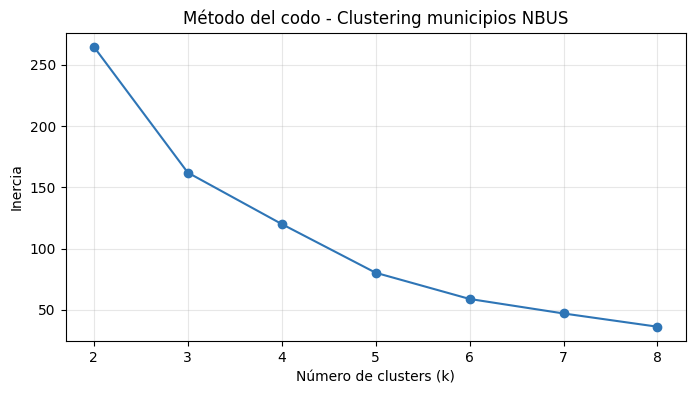

Gráfico del codo guardado en output/metodo_codo.png

--- Perfil medio de cada cluster ---
         poblacion_municipio  num_paradas_municipio  trips_unicos  cobertura_relativa  servicios_por_1000_hab
cluster                                                                                                      
0                    1915.06                   2.06         21.75               33.02                   18.23
1                   24731.50                   4.50        212.00                3.18                   12.84
2                     474.67                  11.67         32.00              352.39                   88.07
3                  207777.00                   8.00        174.00                0.39                    0.59

--- Municipios por cluster ---
cluster
0    71
1     2
2     3
3     1
Name: count, dtype: int64

--- Municipios en cada cluster ---

Cluster 0 (71 municipios): Ablitas, Adiós, Altsasu, Añorbe, Arbizu, Arguedas, Arruazu, Artajona, Bakaiku, Barásoain

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────
# 1. Cargar datos (solo 2024, solo municipios con parada)
# ──────────────────────────────────────────────
df = pd.read_csv('cobertura_municipios.csv')
df_2024 = df[df['year'] == 2024].copy()

# Separar municipios con y sin servicio
df_con_servicio = df_2024[df_2024['tiene_parada'] == True].copy()
df_sin_servicio = df_2024[df_2024['tiene_parada'] == False].copy()

print(f"Municipios con servicio: {len(df_con_servicio)}")
print(f"Municipios sin servicio: {len(df_sin_servicio)}")

# ──────────────────────────────────────────────
# 2. Seleccionar variables para clustering
# ──────────────────────────────────────────────
features = [
    'poblacion_municipio',
    'num_paradas_municipio',
    'trips_unicos',
    'cobertura_relativa',
    'servicios_por_1000_hab'
]

X = df_con_servicio[features].copy()

# ──────────────────────────────────────────────
# 3. Normalizar (imprescindible para K-Means)
# ──────────────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ──────────────────────────────────────────────
# 4. Método del codo para elegir k
# ──────────────────────────────────────────────
inercias = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inercias, marker='o', color='#2E75B6')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia')
plt.title('Método del codo - Clustering municipios NBUS')
plt.grid(True, alpha=0.3)
plt.savefig('metodo_codo.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfico del codo guardado en output/metodo_codo.png")

# ──────────────────────────────────────────────
# 5. Aplicar K-Means con k=4
# ──────────────────────────────────────────────
km = KMeans(n_clusters=4, random_state=42, n_init=10)
df_con_servicio['cluster'] = km.fit_predict(X_scaled)

# ──────────────────────────────────────────────
# 6. Analizar los clusters (para nombrarlos)
# ──────────────────────────────────────────────
print("\n--- Perfil medio de cada cluster ---")
perfil = df_con_servicio.groupby('cluster')[features].mean().round(2)
print(perfil.to_string())

print("\n--- Municipios por cluster ---")
print(df_con_servicio['cluster'].value_counts().sort_index())

print("\n--- Municipios en cada cluster ---")
for c in sorted(df_con_servicio['cluster'].unique()):
    munis = df_con_servicio[df_con_servicio['cluster'] == c]['municipio_mapa'].tolist()
    print(f"\nCluster {c} ({len(munis)} municipios): {', '.join(munis)}")


# ──────────────────────────────────────────────
# 7. Nombrar los clusters
# ──────────────────────────────────────────────
nombres_cluster = {
    0: 'Servicio estándar',
    1: 'Hub secundario',
    2: 'Sobreservido',
    3: 'Capital / Hub principal'
}
df_con_servicio['perfil_cluster'] = df_con_servicio['cluster'].map(nombres_cluster)

# Municipios sin servicio tienen su propio perfil
df_sin_servicio['cluster'] = -1
df_sin_servicio['perfil_cluster'] = 'Sin servicio'

# Unir todo
df_resultado = pd.concat([df_con_servicio, df_sin_servicio], ignore_index=True)

# Exportar
df_resultado.to_csv('output_clusters.csv', index=False)
print(f"\nArchivo exportado: output_clusters.csv")
print(f"Total filas: {len(df_resultado)}")
print(f"\nDistribución de clusters:")
print(df_resultado['perfil_cluster'].value_counts())

### Validación cuantitativa del clustering: silhouette score


In [ ]:
from sklearn.metrics import silhouette_score, silhouette_samples
import numpy as np

# ──────────────────────────────────────────────
# Silhouette score para el k elegido (k=4) y para el resto de k evaluados
# en el método del codo, como validación cuantitativa complementaria.
# ──────────────────────────────────────────────
sil_scores = {}
for k in K_range:
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km_k.fit_predict(X_scaled)
    sil_scores[k] = silhouette_score(X_scaled, labels_k)

print("--- Silhouette score por k ---")
for k, s in sil_scores.items():
    marca = "  <-- k elegido" if k == 4 else ""
    print(f"k={k}: silhouette={s:.3f}{marca}")

plt.figure(figsize=(8, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', color='#C0504D')
plt.axvline(4, color='gray', linestyle='--', alpha=0.5)
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score por número de clusters - Clustering municipios NBUS')
plt.grid(True, alpha=0.3)
plt.savefig('silhouette_score.png', dpi=150, bbox_inches='tight')
plt.show()

# Silhouette por muestra para el k=4 final (para detectar municipios mal asignados)
sil_samples_k4 = silhouette_samples(X_scaled, df_con_servicio['cluster'])
df_con_servicio['silhouette'] = sil_samples_k4
print(f"\nSilhouette medio (k=4): {sil_scores[4]:.3f}")
print("\nMunicipios peor asignados (silhouette más bajo):")
print(df_con_servicio.sort_values('silhouette')[['municipio_mapa','cluster','perfil_cluster','silhouette']].head(5).to_string(index=False))


# Actualizamos cobertura_municipios.csv



In [ ]:
import pandas as pd

# Cargar el resultado del clustering (solo 2024, 272 municipios)
clusters = pd.read_csv('output_clusters.csv')[['cod_municipio', 'cluster', 'perfil_cluster']]

# Cargar cobertura_municipios completo (todos los años)
df = pd.read_csv('cobertura_municipios.csv')

# Añadir cluster (es estructural, aplica a todos los años)
df = df.merge(clusters, on='cod_municipio', how='left')

# Verificar
print(df[['municipio_mapa', 'year', 'perfil_cluster']].head(10))
print(f"\nDistribución:")
print(df['perfil_cluster'].value_counts())

# Re-exportar
df.to_csv('cobertura_municipios.csv', index=False, decimal='.')
print("\ncobertura_municipios.csv actualizado con clusters")

       municipio_mapa  year perfil_cluster
0             Abáigar  2018   Sin servicio
1             Abáigar  2019   Sin servicio
2             Abáigar  2020   Sin servicio
3             Abáigar  2021   Sin servicio
4             Abáigar  2022   Sin servicio
5             Abáigar  2023   Sin servicio
6             Abáigar  2024   Sin servicio
7  Abárzuza/Abartzuza  2018   Sin servicio
8  Abárzuza/Abartzuza  2019   Sin servicio
9  Abárzuza/Abartzuza  2020   Sin servicio

Distribución:
perfil_cluster
Sin servicio               1365
Servicio estándar           497
Sobreservido                 21
Hub secundario               14
Capital / Hub principal       7
Name: count, dtype: int64

cobertura_municipios.csv actualizado con clusters


##  Fase 2 – Predicción de demanda (ML supervisado)

In [ ]:
import pandas as pd

df = pd.read_csv('resumen_por_ruta.csv')
print("Columnas disponibles:")
print(df.columns.tolist())
print(f"\nFilas: {len(df)}")
print(f"\nEstadísticas:")
print(df.describe().round(2))

Columnas disponibles:
['route_id', 'route_short_name', 'route_long_name', 'route_type', 'agency_name', 'exp_ida', 'exp_vuelta', 'num_paradas_unicas', 'num_bajo_peticion', 'pct_bajo_peticion', 'distancia_media_km', 'hora_primera', 'hora_ultima', 'tiempo_recorrido_medio_min', 'num_expediciones', 'num_dias_activo', 'frecuencia_diaria_media']

Filas: 32

Estadísticas:
       route_id  route_short_name  route_type  exp_ida  exp_vuelta  \
count     32.00             32.00        32.0    32.00       32.00   
mean     340.09            340.09         3.0     8.00        7.38   
std       20.90             20.90         0.0     5.59        4.91   
min      300.00            300.00         3.0     1.00        0.00   
25%      325.75            325.75         3.0     3.00        3.00   
50%      333.50            333.50         3.0     6.50        6.00   
75%      354.25            354.25         3.0    11.25       11.00   
max      375.00            375.00         3.0    21.00       18.00   

  

Rutas: 32

--- IDE por ruta (top 10) ---
                               route_long_name       ide
                Pamplona/Iruña-Tudela-Zaragoza 81.176442
          Pamplona/Iruña-Soria (por autopista) 72.725337
    Pamplona/Iruña - Vitoria-Gasteiz (Paradas) 55.803621
          Tafalla - Pamplona/Iruña (carretera) 55.709807
Pamplona/Iruña - Vitoria-Gasteiz (Semidirecto) 53.554933
          Pamplona/Iruña-Soria (por carretera) 53.108108
                             Marcilla -Tafalla 49.027493
  Olite/Erriberri - Pamplona/Iruña (autopista) 48.024015
                             Figarol - Tafalla 47.732755
                             Tarazona - Tudela 47.195915

--- Métricas (Leave-One-Out) ---
MAE:  6.16
R²:   0.756


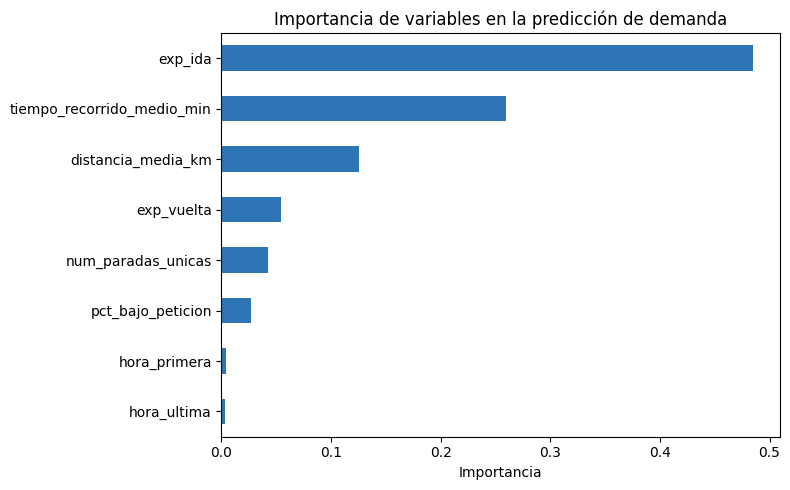


Gráfico guardado en output/feature_importance.png


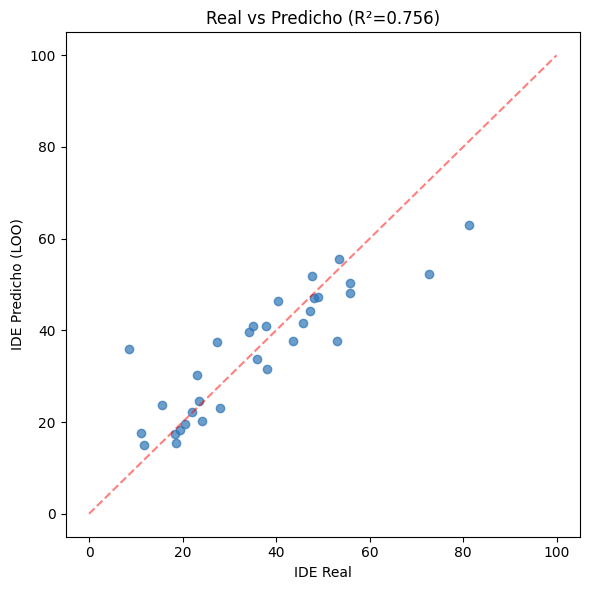


Archivo exportado: output/output_demanda.csv

--- Top 5 rutas con mayor brecha ---
      route_long_name       ide  demanda_predicha  brecha
Baños Fitero - Tudela 40.493720         41.049999    0.56
    Arakil - Irurtzun 15.638809         16.150000    0.51
      Lerín - Larraga 11.086366         11.410000    0.32
     Olleta - Tafalla 19.416805         19.730000    0.31
 Villafranca - Tudela 35.128989         35.380001    0.25

--- Top 5 rutas con menor brecha ---
                 route_long_name       ide  demanda_predicha  brecha
       Miranda de Arga - Tafalla 28.040593         27.410000   -0.63
  Pamplona/Iruña-Tudela-Zaragoza 81.176442         80.779999   -0.40
               Echagüe - Tafalla 22.082834         21.719999   -0.36
             Ujué/Uxue - Tafalla 18.565196         18.290001   -0.28
Puente la Reina/Gares - Campanas 24.118243         23.840000   -0.28


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

# ──────────────────────────────────────────────
# 1. Cargar datos
# ──────────────────────────────────────────────
df = pd.read_csv('resumen_por_ruta.csv')

# Corregir pct_bajo_peticion (debe ser 0-100)
df['pct_bajo_peticion'] = (
    df['num_bajo_peticion'] / df['num_paradas_unicas'] * 100
).round(2).fillna(0)

print(f"Rutas: {len(df)}")

# ──────────────────────────────────────────────
# 2. Crear Índice de Demanda Estimada (IDE)
# ──────────────────────────────────────────────
def norm(s):
    r = s.max() - s.min()
    if r == 0: return s * 0
    return (s - s.min()) / r

df['ide'] = (
    0.35 * norm(df['num_expediciones']) +
    0.25 * norm(df['num_paradas_unicas']) +
    0.20 * norm(df['num_dias_activo']) +
    0.10 * norm(df['distancia_media_km']) +
    0.10 * norm(df['tiempo_recorrido_medio_min'])
) * 100

print("\n--- IDE por ruta (top 10) ---")
print(df[['route_long_name', 'ide']].sort_values('ide', ascending=False).head(10).to_string(index=False))

# ──────────────────────────────────────────────
# 3. Definir features y target
# ──────────────────────────────────────────────
features = [
    'num_paradas_unicas',
    'distancia_media_km',
    'tiempo_recorrido_medio_min',
    'pct_bajo_peticion',
    'hora_primera',
    'hora_ultima',
    'exp_ida',
    'exp_vuelta'
]

X = df[features]
y = df['ide']

# ──────────────────────────────────────────────
# 4. Entrenar con Leave-One-Out (mejor para n=32)
# ──────────────────────────────────────────────
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Leave-One-Out: entrena con 31, predice 1, repite 32 veces
loo = LeaveOneOut()
y_pred = cross_val_predict(model, X, y, cv=loo)

# Métricas
mae = mean_absolute_error(y, y_pred)
r2 = r2_score(y, y_pred)
print(f"\n--- Métricas (Leave-One-Out) ---")
print(f"MAE:  {mae:.2f}")
print(f"R²:   {r2:.3f}")

# ──────────────────────────────────────────────
# 5. Entrenar modelo final (con todos los datos)
# ──────────────────────────────────────────────
model.fit(X, y)
df['demanda_predicha'] = model.predict(X).round(2)
df['brecha'] = (df['demanda_predicha'] - df['ide']).round(2)

# ──────────────────────────────────────────────
# 6. Feature importance
# ──────────────────────────────────────────────
feat_imp = pd.Series(model.feature_importances_, index=features)
feat_imp = feat_imp.sort_values(ascending=True)

plt.figure(figsize=(8, 5))
feat_imp.plot(kind='barh', color='#2E75B6')
plt.title('Importancia de variables en la predicción de demanda')
plt.xlabel('Importancia')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nGráfico guardado en output/feature_importance.png")

# ──────────────────────────────────────────────
# 7. Gráfico Real vs Predicho
# ──────────────────────────────────────────────
plt.figure(figsize=(6, 6))
plt.scatter(df['ide'], y_pred, color='#2E75B6', alpha=0.7)
plt.plot([0, 100], [0, 100], '--', color='red', alpha=0.5)
plt.xlabel('IDE Real')
plt.ylabel('IDE Predicho (LOO)')
plt.title(f'Real vs Predicho (R²={r2:.3f})')
plt.tight_layout()
plt.savefig('real_vs_predicho.png', dpi=150, bbox_inches='tight')
plt.show()

# ──────────────────────────────────────────────
# 8. Exportar
# ──────────────────────────────────────────────
df.to_csv('output_demanda.csv', index=False, decimal='.')
print(f"\nArchivo exportado: output/output_demanda.csv")
print(f"\n--- Top 5 rutas con mayor brecha ---")
print(df[['route_long_name', 'ide', 'demanda_predicha', 'brecha']]
      .sort_values('brecha', ascending=False).head(5).to_string(index=False))
print(f"\n--- Top 5 rutas con menor brecha ---")
print(df[['route_long_name', 'ide', 'demanda_predicha', 'brecha']]
      .sort_values('brecha').head(5).to_string(index=False))

### Modelos baseline de comparación


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

# ──────────────────────────────────────────────
# Baselines para contextualizar el R²=0.756 del XGBoost:
#  1) Media global (predictor ingenuo)
#  2) Regresión lineal sobre las mismas features
# Misma validación (Leave-One-Out) para comparar en igualdad de condiciones.
# ──────────────────────────────────────────────
dummy = DummyRegressor(strategy='mean')
y_pred_dummy = cross_val_predict(dummy, X, y, cv=loo)
mae_dummy = mean_absolute_error(y, y_pred_dummy)
r2_dummy = r2_score(y, y_pred_dummy)

lr = LinearRegression()
y_pred_lr = cross_val_predict(lr, X, y, cv=loo)
mae_lr = mean_absolute_error(y, y_pred_lr)
r2_lr = r2_score(y, y_pred_lr)

comparacion = pd.DataFrame({
    'modelo': ['Media global (baseline)', 'Regresión lineal (baseline)', 'XGBoost (modelo actual)'],
    'MAE_LOO_CV': [round(mae_dummy, 2), round(mae_lr, 2), round(mae, 2)],
    'R2_LOO_CV': [round(r2_dummy, 3), round(r2_lr, 3), round(r2, 3)],
})
print(comparacion.to_string(index=False))
comparacion.to_csv('comparacion_baseline.csv', index=False)

# La regresión lineal iguala o supera al XGBoost: el IDE es, por construcción,
# una combinación LINEAL de features, por lo que un modelo lineal lo recupera
# de forma casi directa. Esto refuerza la lectura de que buena parte de la
# capacidad predictiva proviene de la propia definición del target (leakage),
# no de una relación no lineal genuina que XGBoost estuviera capturando mejor.


# Fase 3 – Asistente Inteligente (IA generativa)

In [ ]:
pip install langchain langchain-openai langchain-experimental openai streamlit python-dotenv tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.8/119.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 65.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 49.9 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.4.3
    Uninstalling langchain-core-1.4.3:
      Successfully uninstalled langchain-core-1.4.3
ERROR: pip's dependency 

In [ ]:
import langchain
import openai
print(f"LangChain: {langchain.__version__}")
print(f"OpenAI: {openai.__version__}")
print("Todo instalado correctamente")

LangChain: 1.3.6
OpenAI: 2.41.0
Todo instalado correctamente


## Cobertura municipios V2

In [ ]:
import pandas as pd

df = pd.read_csv('cobertura_municipios.csv')

def nivel_acceso(row):
    pob = row['poblacion_municipio']
    paradas = row['num_paradas_municipio']

    if paradas == 0:
        return 'Sin acceso'

    if pob > 20000:
        esperado_alto, esperado_medio = 5, 2
    elif pob > 5000:
        esperado_alto, esperado_medio = 4, 2
    elif pob > 1000:
        esperado_alto, esperado_medio = 3, 1
    else:
        esperado_alto, esperado_medio = 2, 1

    if paradas >= esperado_alto:
        return 'Alto acceso'
    elif paradas >= esperado_medio:
        return 'Acceso medio'
    else:
        return 'Bajo acceso'

df['nivel_acceso'] = df.apply(nivel_acceso, axis=1)

# Verificación
df_2024 = df[df['year'] == 2024]
print("Distribución 2024:")
print(df_2024['nivel_acceso'].value_counts())

print("\nPamplona y Tudela 2024:")
print(df_2024[df_2024['municipio_mapa'].isin(['Pamplona', 'Tudela'])]
      [['municipio_mapa', 'poblacion_municipio', 'num_paradas_municipio', 'nivel_acceso']])

# Exportar
df.to_csv('cobertura_municipios.csv', index=False, decimal='.')
print("\ncobertura_municipios.csv actualizado con 'nivel_acceso'")

Distribución 2024:
nivel_acceso
Sin acceso      195
Acceso medio     39
Alto acceso      36
Bajo acceso       2
Name: count, dtype: int64

Pamplona y Tudela 2024:
     municipio_mapa  poblacion_municipio  num_paradas_municipio  nivel_acceso
1406       Pamplona               207777                      8   Alto acceso
1616         Tudela                38685                      3  Acceso medio

cobertura_municipios.csv actualizado con 'nivel_acceso'
